| Nama              | NRP        |
|-------------------|------------|
| Muhammad Dayyan Ghazanfar Latief         | 5054241036     |

<center><strong>Natural Language Processing</strong><br />
<strong><font color="blue">Semester Genap ITS</font></strong><br />
</center>

## Import Library

In [45]:
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Bidirectional, Dense, Dropout, Conv1D, GlobalMaxPooling1D
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

nltk.download('punkt')
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

[nltk_data] Downloading package punkt to /usr/share/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## Load Dataset

In [46]:
df_path = "/kaggle/input/datasets/hiteshyadavx/tweet-emotion-recognition/"

train_df = pd.read_csv(os.path.join(df_path, 'train.csv'))
val_df   = pd.read_csv(os.path.join(df_path, 'val.csv'))
test_df  = pd.read_csv(os.path.join(df_path, 'test.csv'))

X_train, y_train = train_df['text'], train_df['label']
X_val, y_val     = val_df['text'], val_df['label']
X_test, y_test   = test_df['text'], test_df['label']

print(f"Jumlah Data -> Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")

Jumlah Data -> Train: 16000 | Val: 2000 | Test: 2000


## Pre-Processing

In [47]:
def preprocess_text(text):
    text = str(text).lower() 
    text = re.sub(r'http\S+|www.\S+', '', text) 
    text = re.sub(r'@\w+', '', text) 
    text = re.sub(r'#\w+', '', text) 
    text = re.sub(r'[^\w\s]', '', text) 
    text = re.sub(r'\d+', '', text) 
    
    tokens = word_tokenize(text) 
    tokens = [word for word in tokens if word not in stop_words] 
    
    return ' '.join(tokens)

print("Memproses teks (cleaning)...")
X_train_clean = X_train.apply(preprocess_text)
X_val_clean   = X_val.apply(preprocess_text)
X_test_clean  = X_test.apply(preprocess_text)
print("Preprocessing selesai!")

Memproses teks (cleaning)...
Preprocessing selesai!


## Feature Extractioon

In [48]:
# 1. Encoding Label 
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_val_enc   = le.transform(y_val)
y_test_enc  = le.transform(y_test)
class_names = [str(c) for c in le.classes_] 

# 2. Persiapan Fitur Machine Learning (TF-IDF)
tfidf = TfidfVectorizer(max_features=5000)
X_train_tfidf = tfidf.fit_transform(X_train_clean) 
X_val_tfidf   = tfidf.transform(X_val_clean)
X_test_tfidf  = tfidf.transform(X_test_clean)

# 3. Persiapan Fitur Deep Learning (Sequence & Padding)
max_words = 5000
max_len = 50

tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train_clean) 

# Padding 'post' untuk CNN 1D
X_train_pad = pad_sequences(tokenizer.texts_to_sequences(X_train_clean), maxlen=max_len, padding='post', truncating='post')
X_val_pad   = pad_sequences(tokenizer.texts_to_sequences(X_val_clean), maxlen=max_len, padding='post', truncating='post')
X_test_pad  = pad_sequences(tokenizer.texts_to_sequences(X_test_clean), maxlen=max_len, padding='post', truncating='post')

# Padding 'pre' khusus untuk LSTM 
X_train_pad_lstm = pad_sequences(tokenizer.texts_to_sequences(X_train_clean), maxlen=max_len, padding='pre', truncating='post')
X_val_pad_lstm   = pad_sequences(tokenizer.texts_to_sequences(X_val_clean), maxlen=max_len, padding='pre', truncating='post')
X_test_pad_lstm  = pad_sequences(tokenizer.texts_to_sequences(X_test_clean), maxlen=max_len, padding='pre', truncating='post')

## Training Model ML

In [49]:
models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM": SVC(kernel='linear')
}

ml_results = {}
print("--- Evaluasi Model ML (Validation Set) ---")
for name, model in models.items():
    model.fit(X_train_tfidf, y_train_enc)
    val_pred = model.predict(X_val_tfidf)
    ml_results[name] = {"model": model, "val_acc": accuracy_score(y_val_enc, val_pred)}
    print(f"{name} Val Acc: {ml_results[name]['val_acc']:.4f}")

# Tuning KNN
best_k, best_knn_acc, best_knn_model = 1, 0, None
for k in [3, 5, 7, 9, 11]:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_tfidf, y_train_enc)
    acc = accuracy_score(y_val_enc, knn.predict(X_val_tfidf))
    if acc > best_knn_acc:
        best_knn_acc, best_k, best_knn_model = acc, k, knn

ml_results["KNN (Tuned)"] = {"model": best_knn_model, "val_acc": best_knn_acc}
print(f"KNN K={best_k} Val Acc: {best_knn_acc:.4f}")

--- Evaluasi Model ML (Validation Set) ---
Naive Bayes Val Acc: 0.7480
Logistic Regression Val Acc: 0.8770
SVM Val Acc: 0.8875
KNN K=11 Val Acc: 0.8230


## Training Model DL

In [50]:
num_classes = len(class_names)
embedding_dim = 64
early_stop = EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)

# 1. LSTM
lstm_model = Sequential([
    Embedding(input_dim=max_words, output_dim=embedding_dim, input_length=max_len),
    Bidirectional(LSTM(64, return_sequences=False)),
    Dropout(0.5),
    Dense(32, activation='relu'),
    Dense(num_classes, activation='softmax')
])
custom_opt = Adam(learning_rate=0.001)
lstm_model.compile(loss='sparse_categorical_crossentropy', optimizer=custom_opt, metrics=['accuracy'])

# 2. CNN 1D
cnn_model = Sequential([
    Embedding(input_dim=max_words, output_dim=embedding_dim, input_length=max_len),
    Conv1D(filters=128, kernel_size=5, activation='relu'),
    GlobalMaxPooling1D(),
    Dropout(0.5),
    Dense(32, activation='relu'),
    Dense(num_classes, activation='softmax')
])
cnn_model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

print("\n--- Training Bidirectional LSTM ---")
lstm_history = lstm_model.fit(X_train_pad_lstm, y_train_enc, epochs=10, validation_data=(X_val_pad_lstm, y_val_enc), callbacks=[early_stop], batch_size=32, verbose=1)

print("\n--- Training CNN 1D ---")
cnn_history = cnn_model.fit(X_train_pad, y_train_enc, epochs=10, validation_data=(X_val_pad, y_val_enc), callbacks=[early_stop], batch_size=32, verbose=1)


--- Training Bidirectional LSTM ---
Epoch 1/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 15s 24ms/step - accuracy: 0.3878 - loss: 1.4984 - val_accuracy: 0.7895 - val_loss: 0.6282
Epoch 2/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 11s 23ms/step - accuracy: 0.8560 - loss: 0.4262 - val_accuracy: 0.9065 - val_loss: 0.2681
Epoch 3/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 11s 23ms/step - accuracy: 0.9461 - loss: 0.1612 - val_accuracy: 0.9100 - val_loss: 0.2696
Epoch 4/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 12s 23ms/step - accuracy: 0.9676 - loss: 0.0976 - val_accuracy: 0.9115 - val_loss: 0.2641
Epoch 5/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 12s 24ms/step - accuracy: 0.9728 - loss: 0.0756 - val_accuracy: 0.9150 - val_loss: 0.3003
Epoch 6/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 11s 23ms/step - accuracy: 0.9757 - loss: 0.0648 - val_accuracy: 0.9130 - val_loss: 0.3182

--- Training CNN 1D ---
Epoch 1/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.4037 - loss: 1.4764 - val_accuracy: 0.8915 - val_loss: 0.3297
Epoch 2/10
500/500 ━━━━━━━━━━

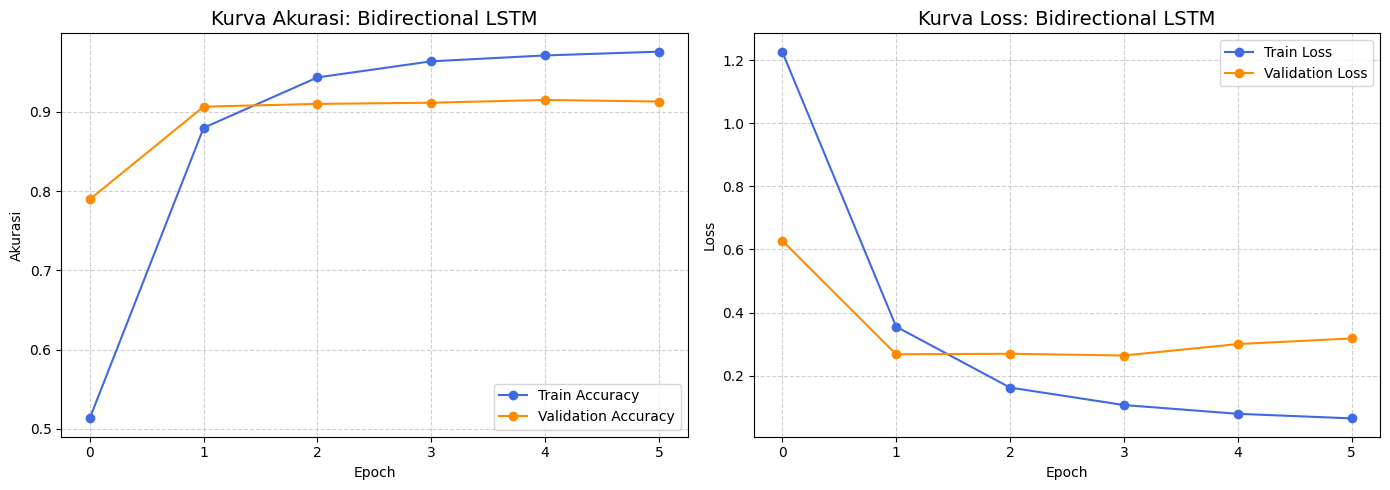

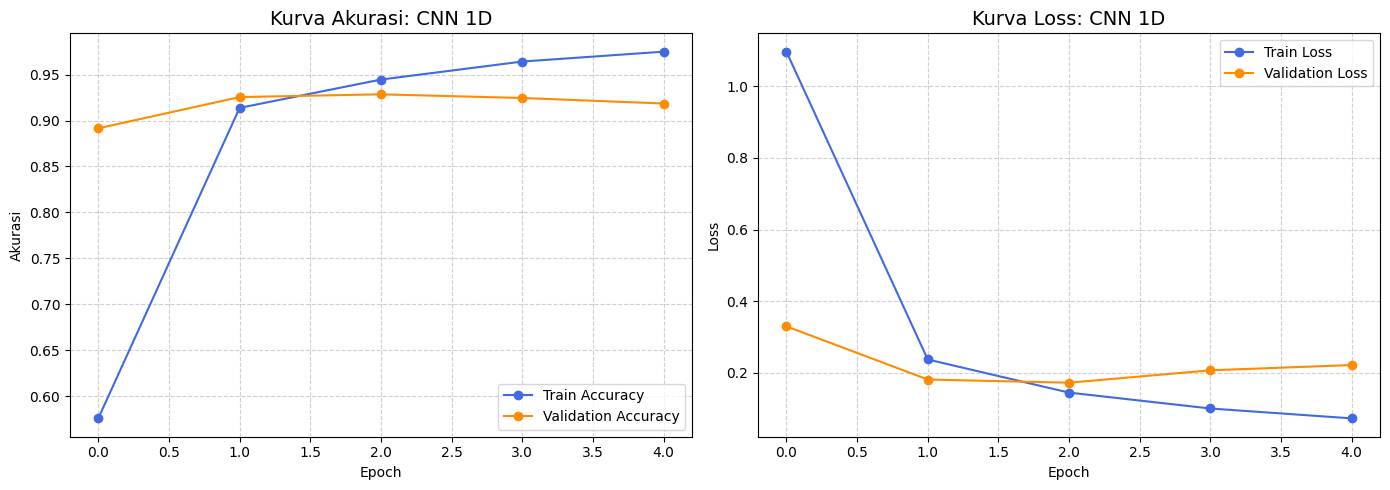

In [51]:
def plot_training_history(history, model_name):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Plot Akurasi
    ax1.plot(history.history['accuracy'], label='Train Accuracy', marker='o', color='royalblue')
    ax1.plot(history.history['val_accuracy'], label='Validation Accuracy', marker='o', color='darkorange')
    ax1.set_title(f'Kurva Akurasi: {model_name}', fontsize=14)
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Akurasi')
    ax1.legend(loc='lower right')
    ax1.grid(True, linestyle='--', alpha=0.6)

    # Plot Loss
    ax2.plot(history.history['loss'], label='Train Loss', marker='o', color='royalblue')
    ax2.plot(history.history['val_loss'], label='Validation Loss', marker='o', color='darkorange')
    ax2.set_title(f'Kurva Loss: {model_name}', fontsize=14)
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Loss')
    ax2.legend(loc='upper right')
    ax2.grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()

plot_training_history(lstm_history, "Bidirectional LSTM")
plot_training_history(cnn_history, "CNN 1D")

## Evaluation & Visualization

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Model Terbaik Keseluruhan: CNN 1D


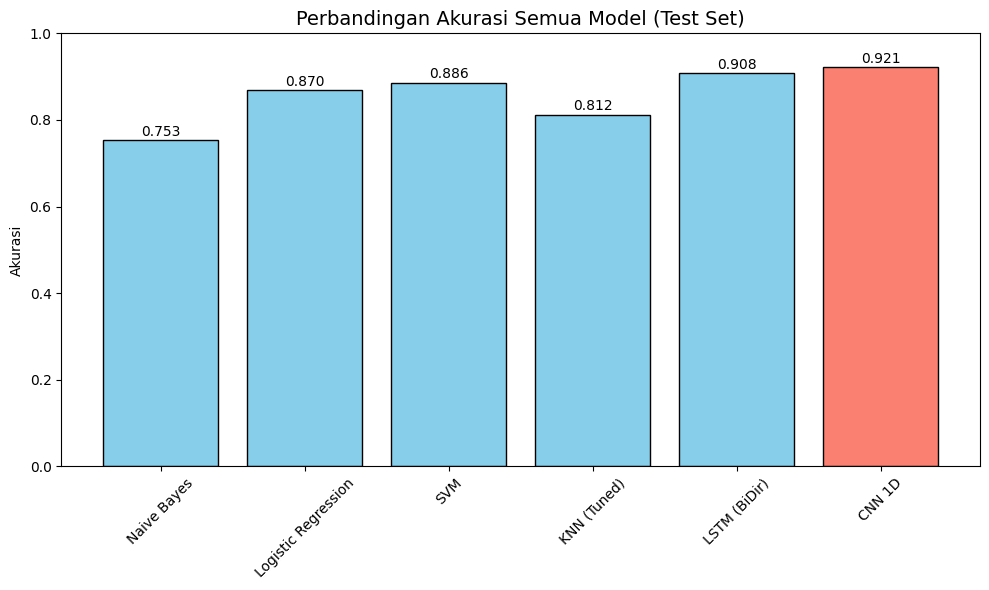

In [52]:
# Hitung Akurasi Test Set
test_accuracies = {name: accuracy_score(y_test_enc, data["model"].predict(X_test_tfidf)) for name, data in ml_results.items()}

lstm_pred = np.argmax(lstm_model.predict(X_test_pad_lstm), axis=1)
cnn_pred = np.argmax(cnn_model.predict(X_test_pad), axis=1)

test_accuracies["LSTM (BiDir)"] = accuracy_score(y_test_enc, lstm_pred)
test_accuracies["CNN 1D"] = accuracy_score(y_test_enc, cnn_pred)

best_model_name = max(test_accuracies, key=test_accuracies.get)
print(f"Model Terbaik Keseluruhan: {best_model_name}")

# Simpan prediksi terbaik untuk divisualisasikan
if best_model_name in ml_results:
    best_pred = ml_results[best_model_name]["model"].predict(X_test_tfidf)
elif best_model_name == "LSTM (BiDir)":
    best_pred = lstm_pred
else:
    best_pred = cnn_pred

plt.figure(figsize=(10, 6))
colors = ['skyblue' if name != best_model_name else 'salmon' for name in test_accuracies.keys()]
bars = plt.bar(test_accuracies.keys(), test_accuracies.values(), color=colors, edgecolor='black')
plt.title('Perbandingan Akurasi Semua Model (Test Set)', fontsize=14)
plt.ylabel('Akurasi')
plt.ylim(0, 1.0)
plt.xticks(rotation=45)

for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f"{bar.get_height():.3f}", ha='center')
    
plt.tight_layout()
plt.show()

--- Laporan Klasifikasi (CNN 1D) ---
              precision    recall  f1-score   support

           0       0.96      0.97      0.96       581
           1       0.95      0.93      0.94       695
           2       0.78      0.85      0.81       159
           3       0.92      0.90      0.91       275
           4       0.89      0.87      0.88       224
           5       0.74      0.85      0.79        66

    accuracy                           0.92      2000
   macro avg       0.87      0.89      0.88      2000
weighted avg       0.92      0.92      0.92      2000



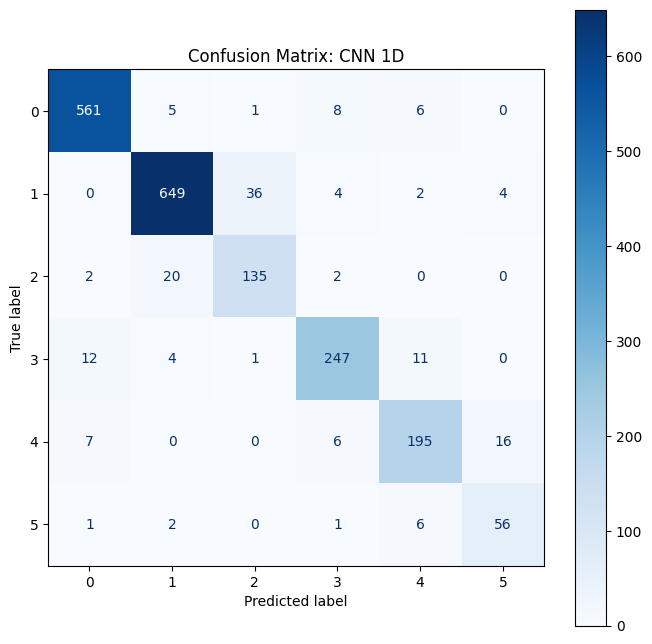

In [53]:
print(f"--- Laporan Klasifikasi ({best_model_name}) ---")
print(classification_report(y_test_enc, best_pred, target_names=class_names))

cm = confusion_matrix(y_test_enc, best_pred)
fig, ax = plt.subplots(figsize=(8, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title(f'Confusion Matrix: {best_model_name}')
plt.show()

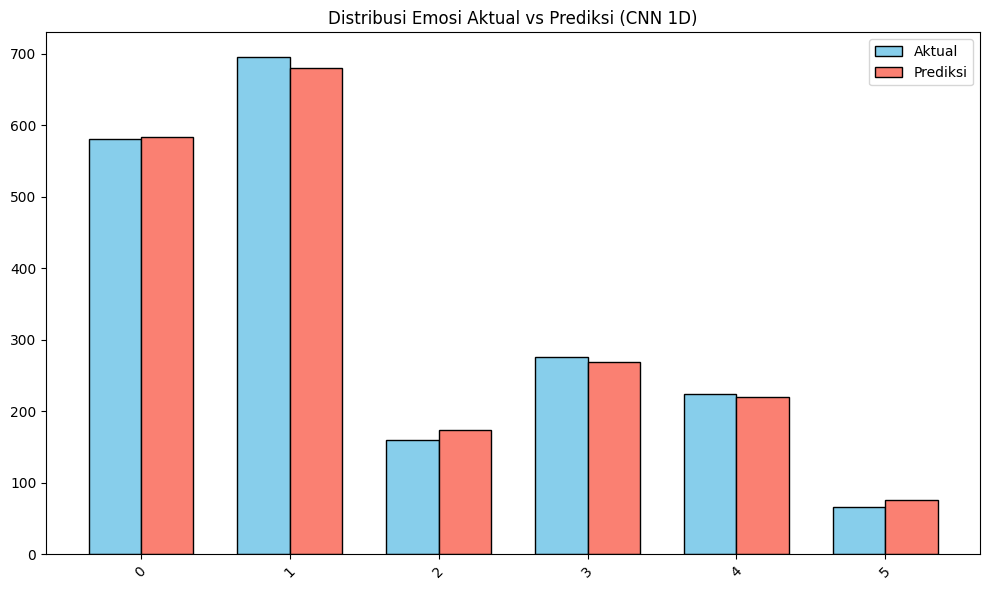

In [54]:
true_text = le.inverse_transform(y_test_enc)
pred_text = le.inverse_transform(best_pred)
true_counts = pd.Series(true_text).value_counts().sort_index()
pred_counts = pd.Series(pred_text).value_counts().sort_index()

x = np.arange(len(true_counts))
fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(x - 0.175, true_counts.values, 0.35, label='Aktual', color='skyblue', edgecolor='black')
ax.bar(x + 0.175, pred_counts.values, 0.35, label='Prediksi', color='salmon', edgecolor='black')
ax.set_title(f'Distribusi Emosi Aktual vs Prediksi ({best_model_name})')
ax.set_xticks(x)
ax.set_xticklabels(true_counts.index, rotation=45)
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
from IPython.display import display

results_df = pd.DataFrame({
    'Tweet Asli': X_test.values,
    'Label Aktual': true_text,
    'Label Prediksi': pred_text
})

results_df['Status'] = np.where(results_df['Label Aktual'] == results_df['Label Prediksi'], '✅ Benar', '❌ Salah')

print(f"--- Tabel Error Analysis ({best_model_name}) ---")
display(results_df.sample(15, random_state=42))

--- Tabel Error Analysis (CNN 1D) ---


,Tweet Asli,Label Aktual,Label Prediksi,Status
1860,i feel so dirty but after spending a day at th...,0,0,✅ Benar
353,i could feel his breath on me and smell the sw...,1,2,❌ Salah
1333,i just want to feel loved by you,2,2,✅ Benar
905,i have felt the need to write out my sometimes...,3,3,✅ Benar
1289,at a party i met a girl who drew me to her,3,4,❌ Salah
1273,i feel this strange sort of liberation,5,4,❌ Salah
938,i remember feeling thrilled to use my nursing ...,1,1,✅ Benar
1731,i always feel sympathetic for those that do as...,2,2,✅ Benar
65,i feel a little stunned but can t imagine what...,5,5,✅ Benar
1323,i feel slytherin is my house slytherin is for ...,1,1,✅ Benar
